In [ ]:
# pip install h2o

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, chi2, RFE, f_classif
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import f_regression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from yellowbrick.classifier import ConfusionMatrix
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel
# import h2o
# from h2o.automl import H2OAutoML ##funciona com modelos de clusters

In [ ]:
data = pd.read_csv('dados8.csv')
data.head()

,Candidate ID,Name,Number of characters in Original Name,Month of Birth,Year of Birth,Gender,State (Location),10th percentage,12th percentage,10th Completion Year,...,Quantitative Ability 3,Quantitative Ability 4,Domain Skills 1,Domain Skills 2,Domain Test 3,Domain Test 4,Analytical Skills 1,Analytical Skills 2,Analytical Skills 3,Performance
0,1131,PtS,13,FEB,Y7,A,N,83.80,84.00,Y13,...,65.363128,63.005780,48.2142857142857,68.345324,68.275862,59.124088,90.9090909090909,81.012658,95.402299,BP
1,130,AyS,11,NOV,Y7,B,D,84.40,77.00,Y14,...,56.424581,65.317919,50,66.906475,68.275862,60.583942,67.2727272727273,88.607595,56.321839,BP
2,882,CiK,13,MAR,Y8,B,N,86.26,62.83,Y14,...,50.837989,52.601156,46.4285714285714,56.834532,72.413793,64.963504,60,79.746835,32.183908,BP
3,28,AhS,12,MAR,Y8,A,F,81.00,72.00,Y14,...,55.307263,56.069364,35.7142857142857,53.956835,71.034483,50.364964,47.2727272727273,73.417722,35.632184,BP
4,239,MnV,25,NOV,Y7,A,E,62.92,68.00,Y14,...,38.547486,61.849711,19.6428571428571,39.568345,43.448276,62.043796,45.4545454545455,60.759494,40.229885,BP


##Estudo inicial do dataframe

In [ ]:
data.shape
##possui 469 linhas e 31 colunas

(469, 31)

In [ ]:
data.info()
##possui tanto colunas categoricas e numericas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 469 entries, 0 to 468
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Candidate ID                           469 non-null    int64  
 1   Name                                   469 non-null    object 
 2   Number of characters in Original Name  469 non-null    int64  
 3   Month of Birth                         469 non-null    object 
 4   Year of Birth                          469 non-null    object 
 5   Gender                                 469 non-null    object 
 6   State (Location)                       469 non-null    object 
 7    10th percentage                       469 non-null    float64
 8    12th percentage                       469 non-null    float64
 9   10th Completion Year                   469 non-null    object 
 10  12th Completion year                   469 non-null    object 
 11  Degree

In [ ]:
data.describe()
##estatisticas para colunas numericas para analise

,Candidate ID,Number of characters in Original Name,10th percentage,12th percentage,College percentage,English 1,English 2,English 3,English 4,Quantitative Ability 2,Quantitative Ability 3,Quantitative Ability 4,Domain Skills 2,Domain Test 3,Domain Test 4,Analytical Skills 2,Analytical Skills 3
count,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000,469.000000
mean,716.976546,13.176972,83.215991,80.515053,72.633198,50.424428,70.085424,65.981779,66.943111,63.289200,60.821193,62.555924,69.049409,62.045438,68.516645,71.083102,62.314046
std,403.041287,3.179230,6.841820,8.937947,7.067401,16.646622,10.728110,11.655084,11.220116,11.679166,10.986086,10.941985,13.965125,13.333236,12.733411,12.815698,17.220136
min,9.000000,8.000000,62.920000,61.000000,55.960000,13.207547,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,29.113924,9.195402
25%,387.000000,11.000000,79.060000,74.200000,67.200000,39.622642,63.057325,58.787879,59.509202,55.688623,55.307263,54.913295,59.712230,54.482759,62.043796,62.025316,50.574713
50%,737.000000,12.000000,84.400000,80.800000,72.240000,49.056604,68.152866,64.848485,66.871166,62.874251,60.893855,61.849711,71.223022,61.379310,69.343066,72.151899,63.218391
75%,1066.000000,15.000000,88.200000,88.200000,77.700000,60.377358,77.070064,73.333333,74.233129,71.257485,67.597765,67.630058,78.417266,71.034483,76.642336,81.012658,75.862069
max,1418.000000,27.000000,96.600000,97.600000,92.700000,100.000000,97.452229,100.000000,100.000000,100.000000,100.000000,94.219653,100.000000,97.241379,95.620438,96.202532,100.000000


In [ ]:
##ver a quantidade de vezes que os valores sao ausentes (aparecem como "MD") por coluna
data[data == 'MD'].count()
##percebe-se que colunas de notas tem 18 MDs e a coluna performance tem 17MDs.
##provavelmente a ideia seria substituir os valores de performance "MD" pela moda
##a ideia de substituir os valores de notas seria pela mediana, fugindo de outliers


,0
Candidate ID,0
Name,0
Number of characters in Original Name,0
Month of Birth,0
Year of Birth,0
Gender,0
State (Location),0
10th percentage,0
12th percentage,0
10th Completion Year,0


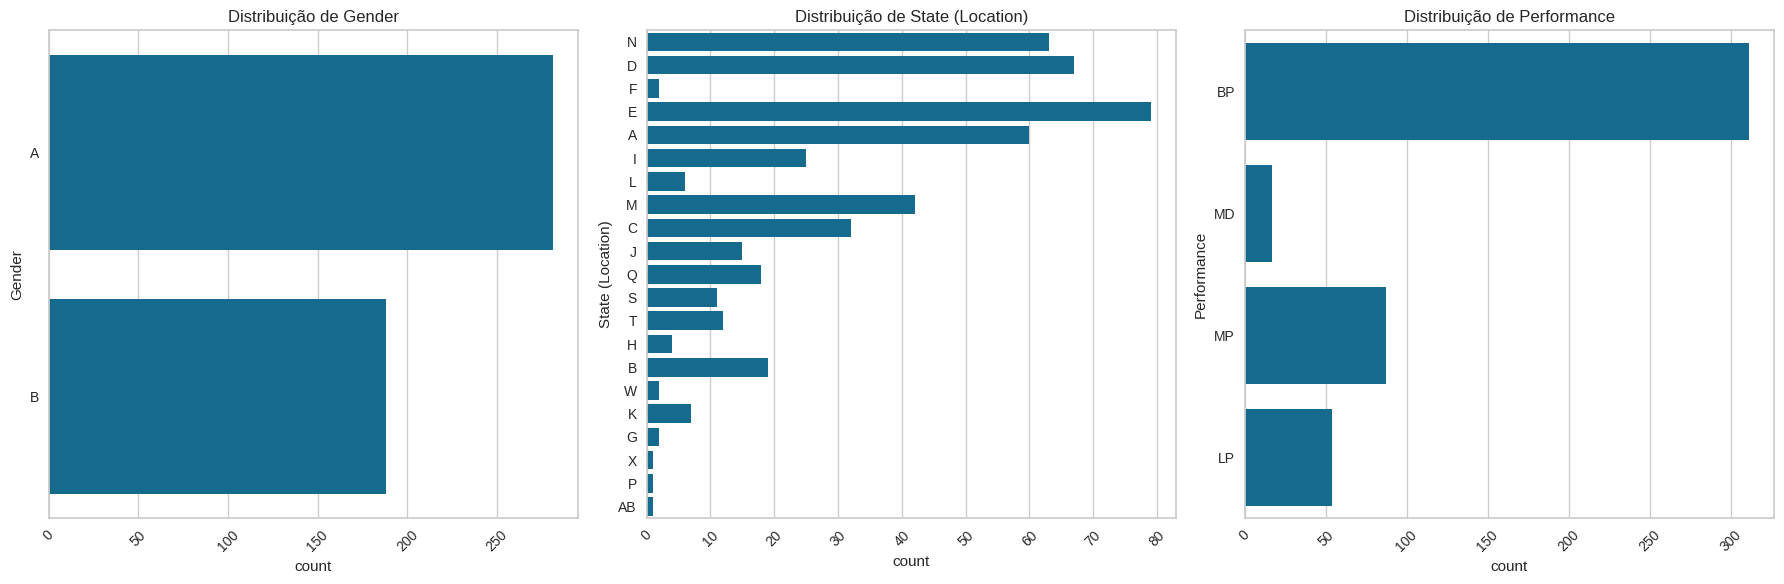

In [ ]:
categorical_columns = ['Gender', 'State (Location)', 'Performance']

plt.figure(figsize=(18, 6))
for i, col in enumerate(categorical_columns, 1):
    plt.subplot(1, len(categorical_columns), i)
    sns.countplot(data[col])
    plt.title(f'Distribuição de {col}')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##cerca de 1/3 a mais de pessoas do genero A
##grande distribuição de cidades, com destaque para N, D, E e A
##Grande maioria das pessoas recebeu uma perfomance BP

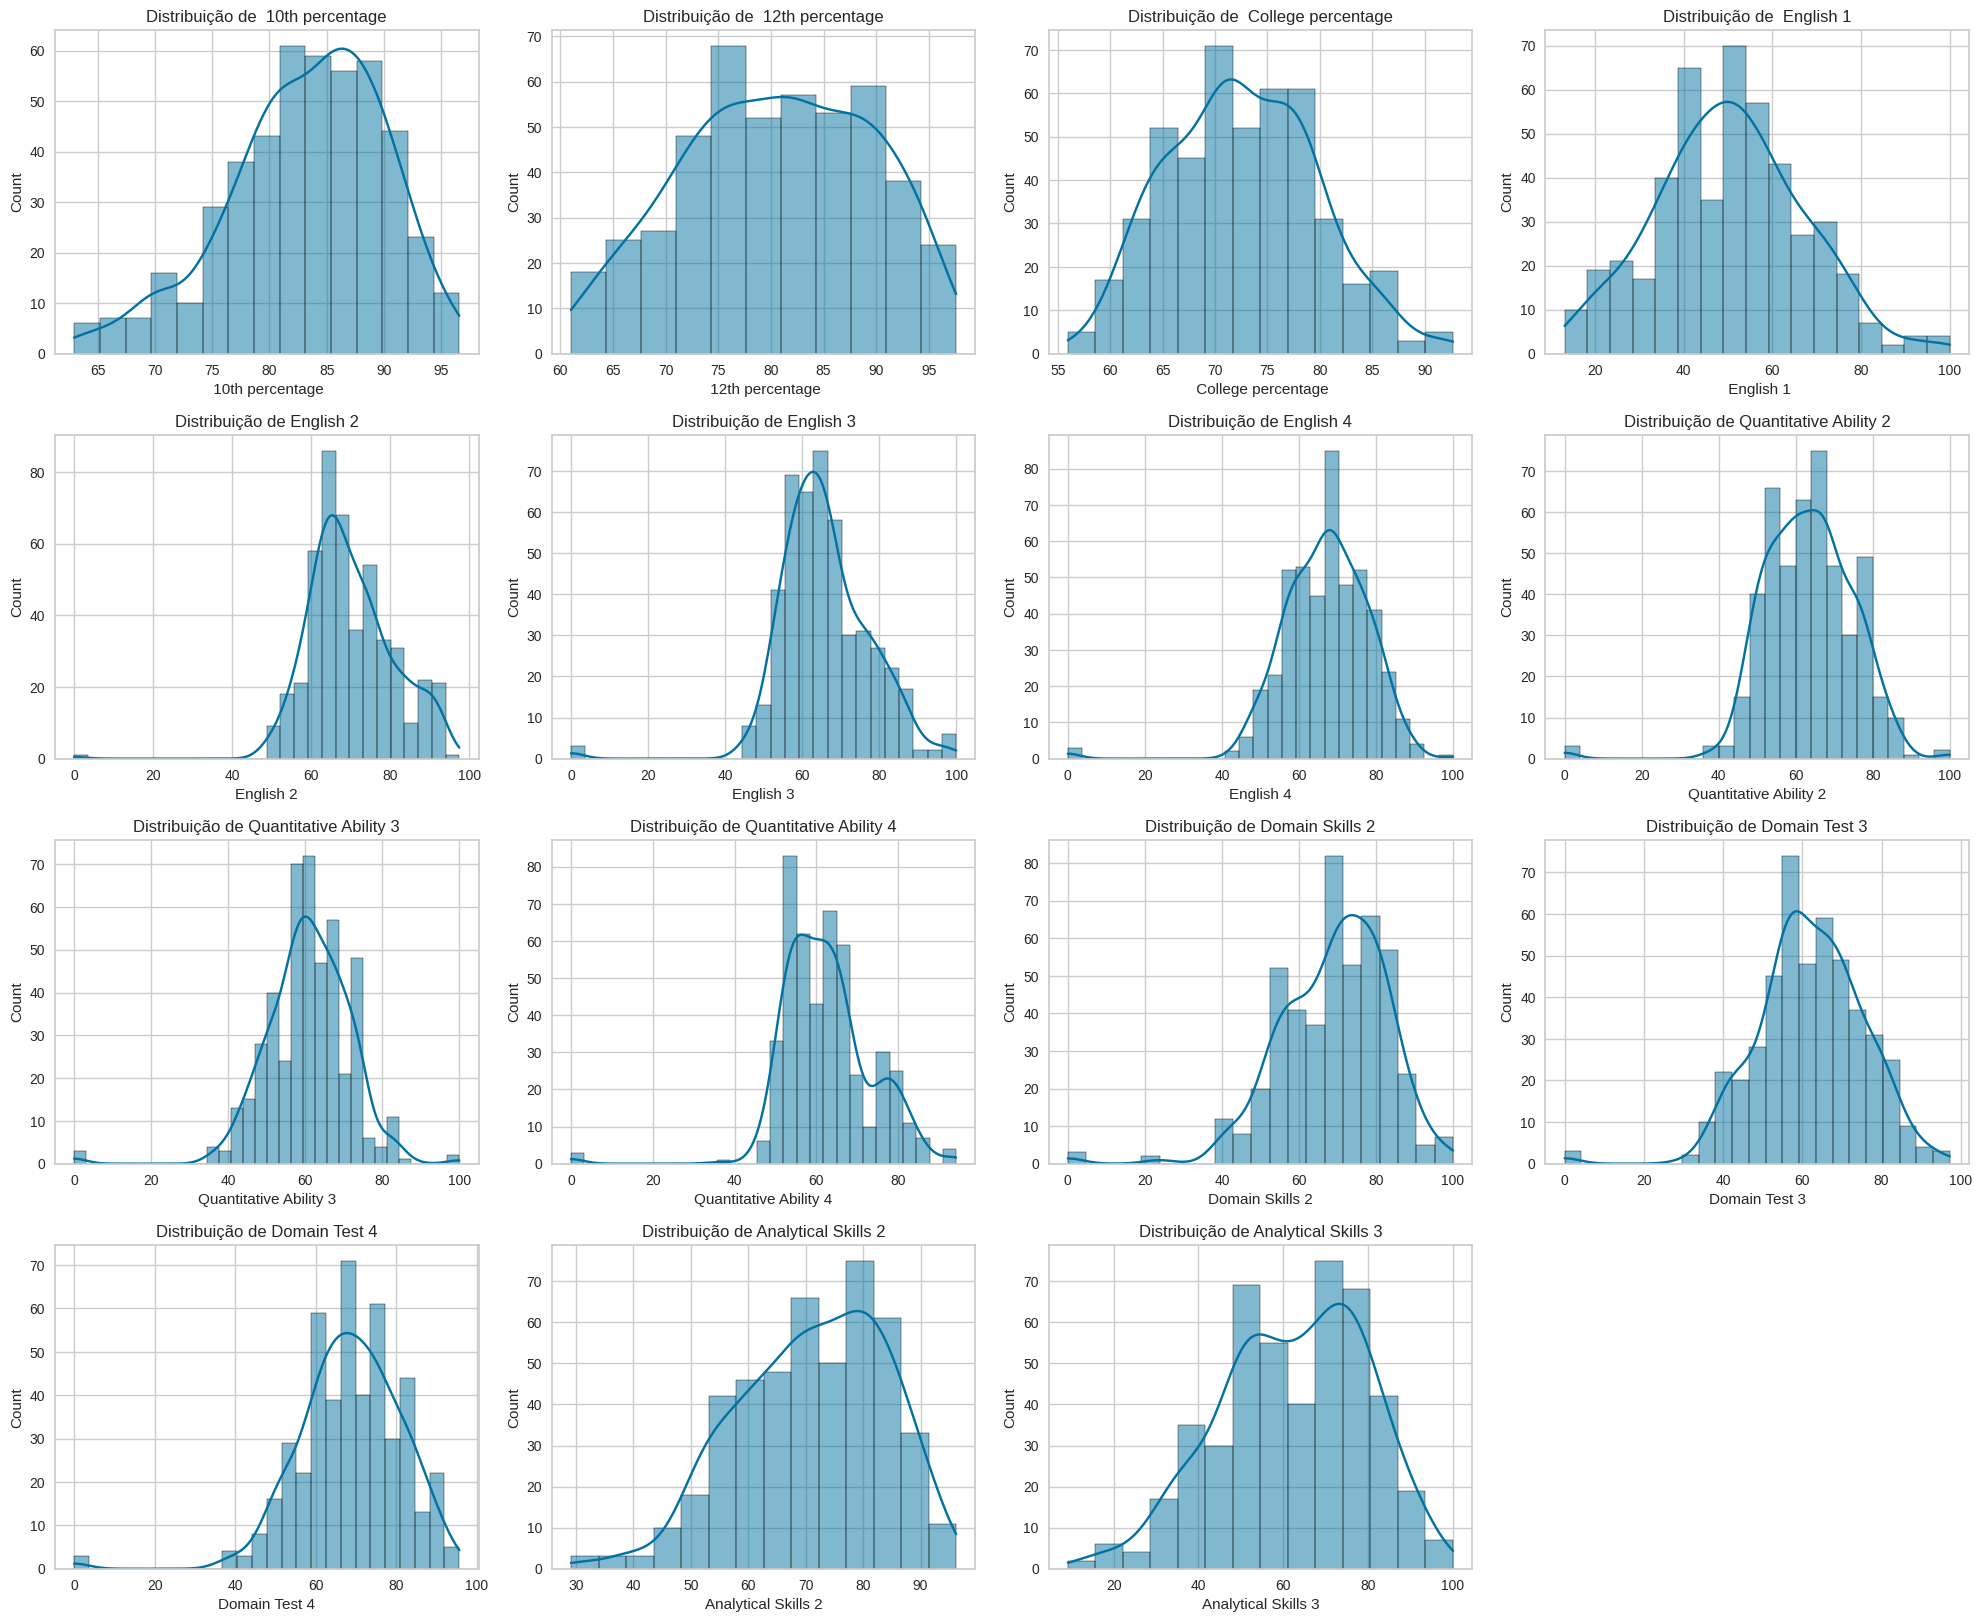

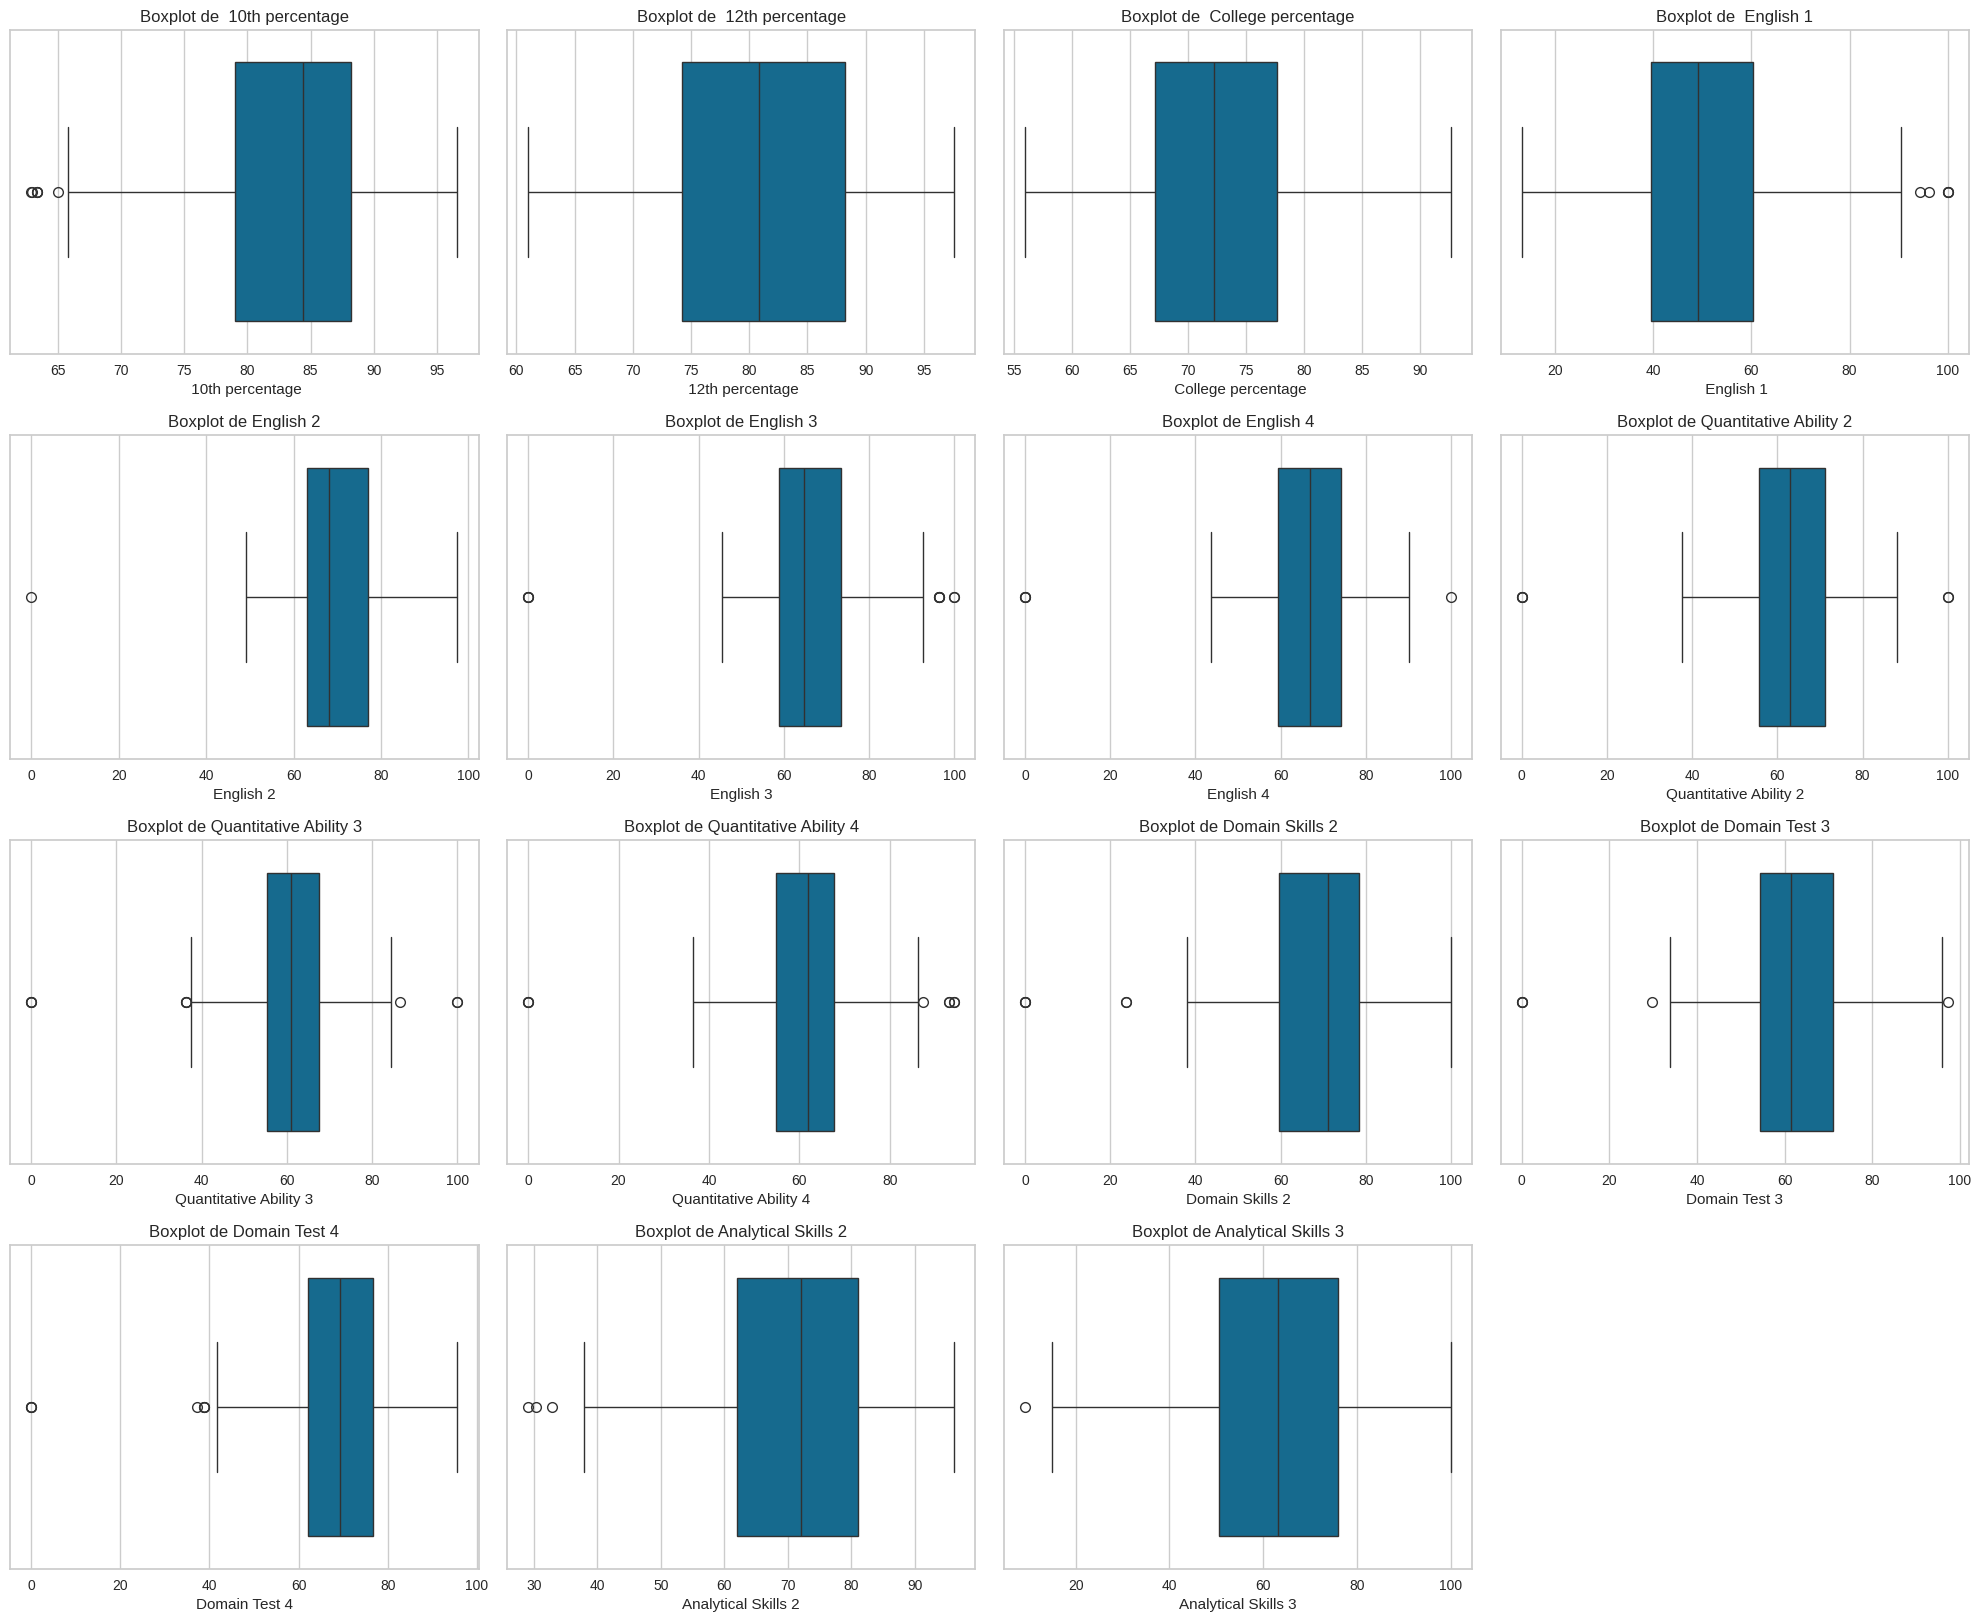

In [ ]:
num_columns = data.select_dtypes(include=[np.number]).columns

numeric_columns = [col for col in num_columns if col not in ['Candidate ID', 'Number of characters in Original Name']]

plt.figure(figsize=(20, 20))
for i, col in enumerate(numeric_columns, 1):
    plt.subplot(5, 4, i)
    sns.histplot(data[col].dropna(), kde=True)
    plt.title(f'Distribuição de {col}')
plt.tight_layout()
plt.show()

# Visualizar possíveis outliers usando boxplots
plt.figure(figsize=(20, 20))
for i, col in enumerate(numeric_columns, 1):
    plt.subplot(5, 4, i)
    sns.boxplot(x=data[col])
    plt.title(f'Boxplot de {col}')
plt.tight_layout()
plt.show()


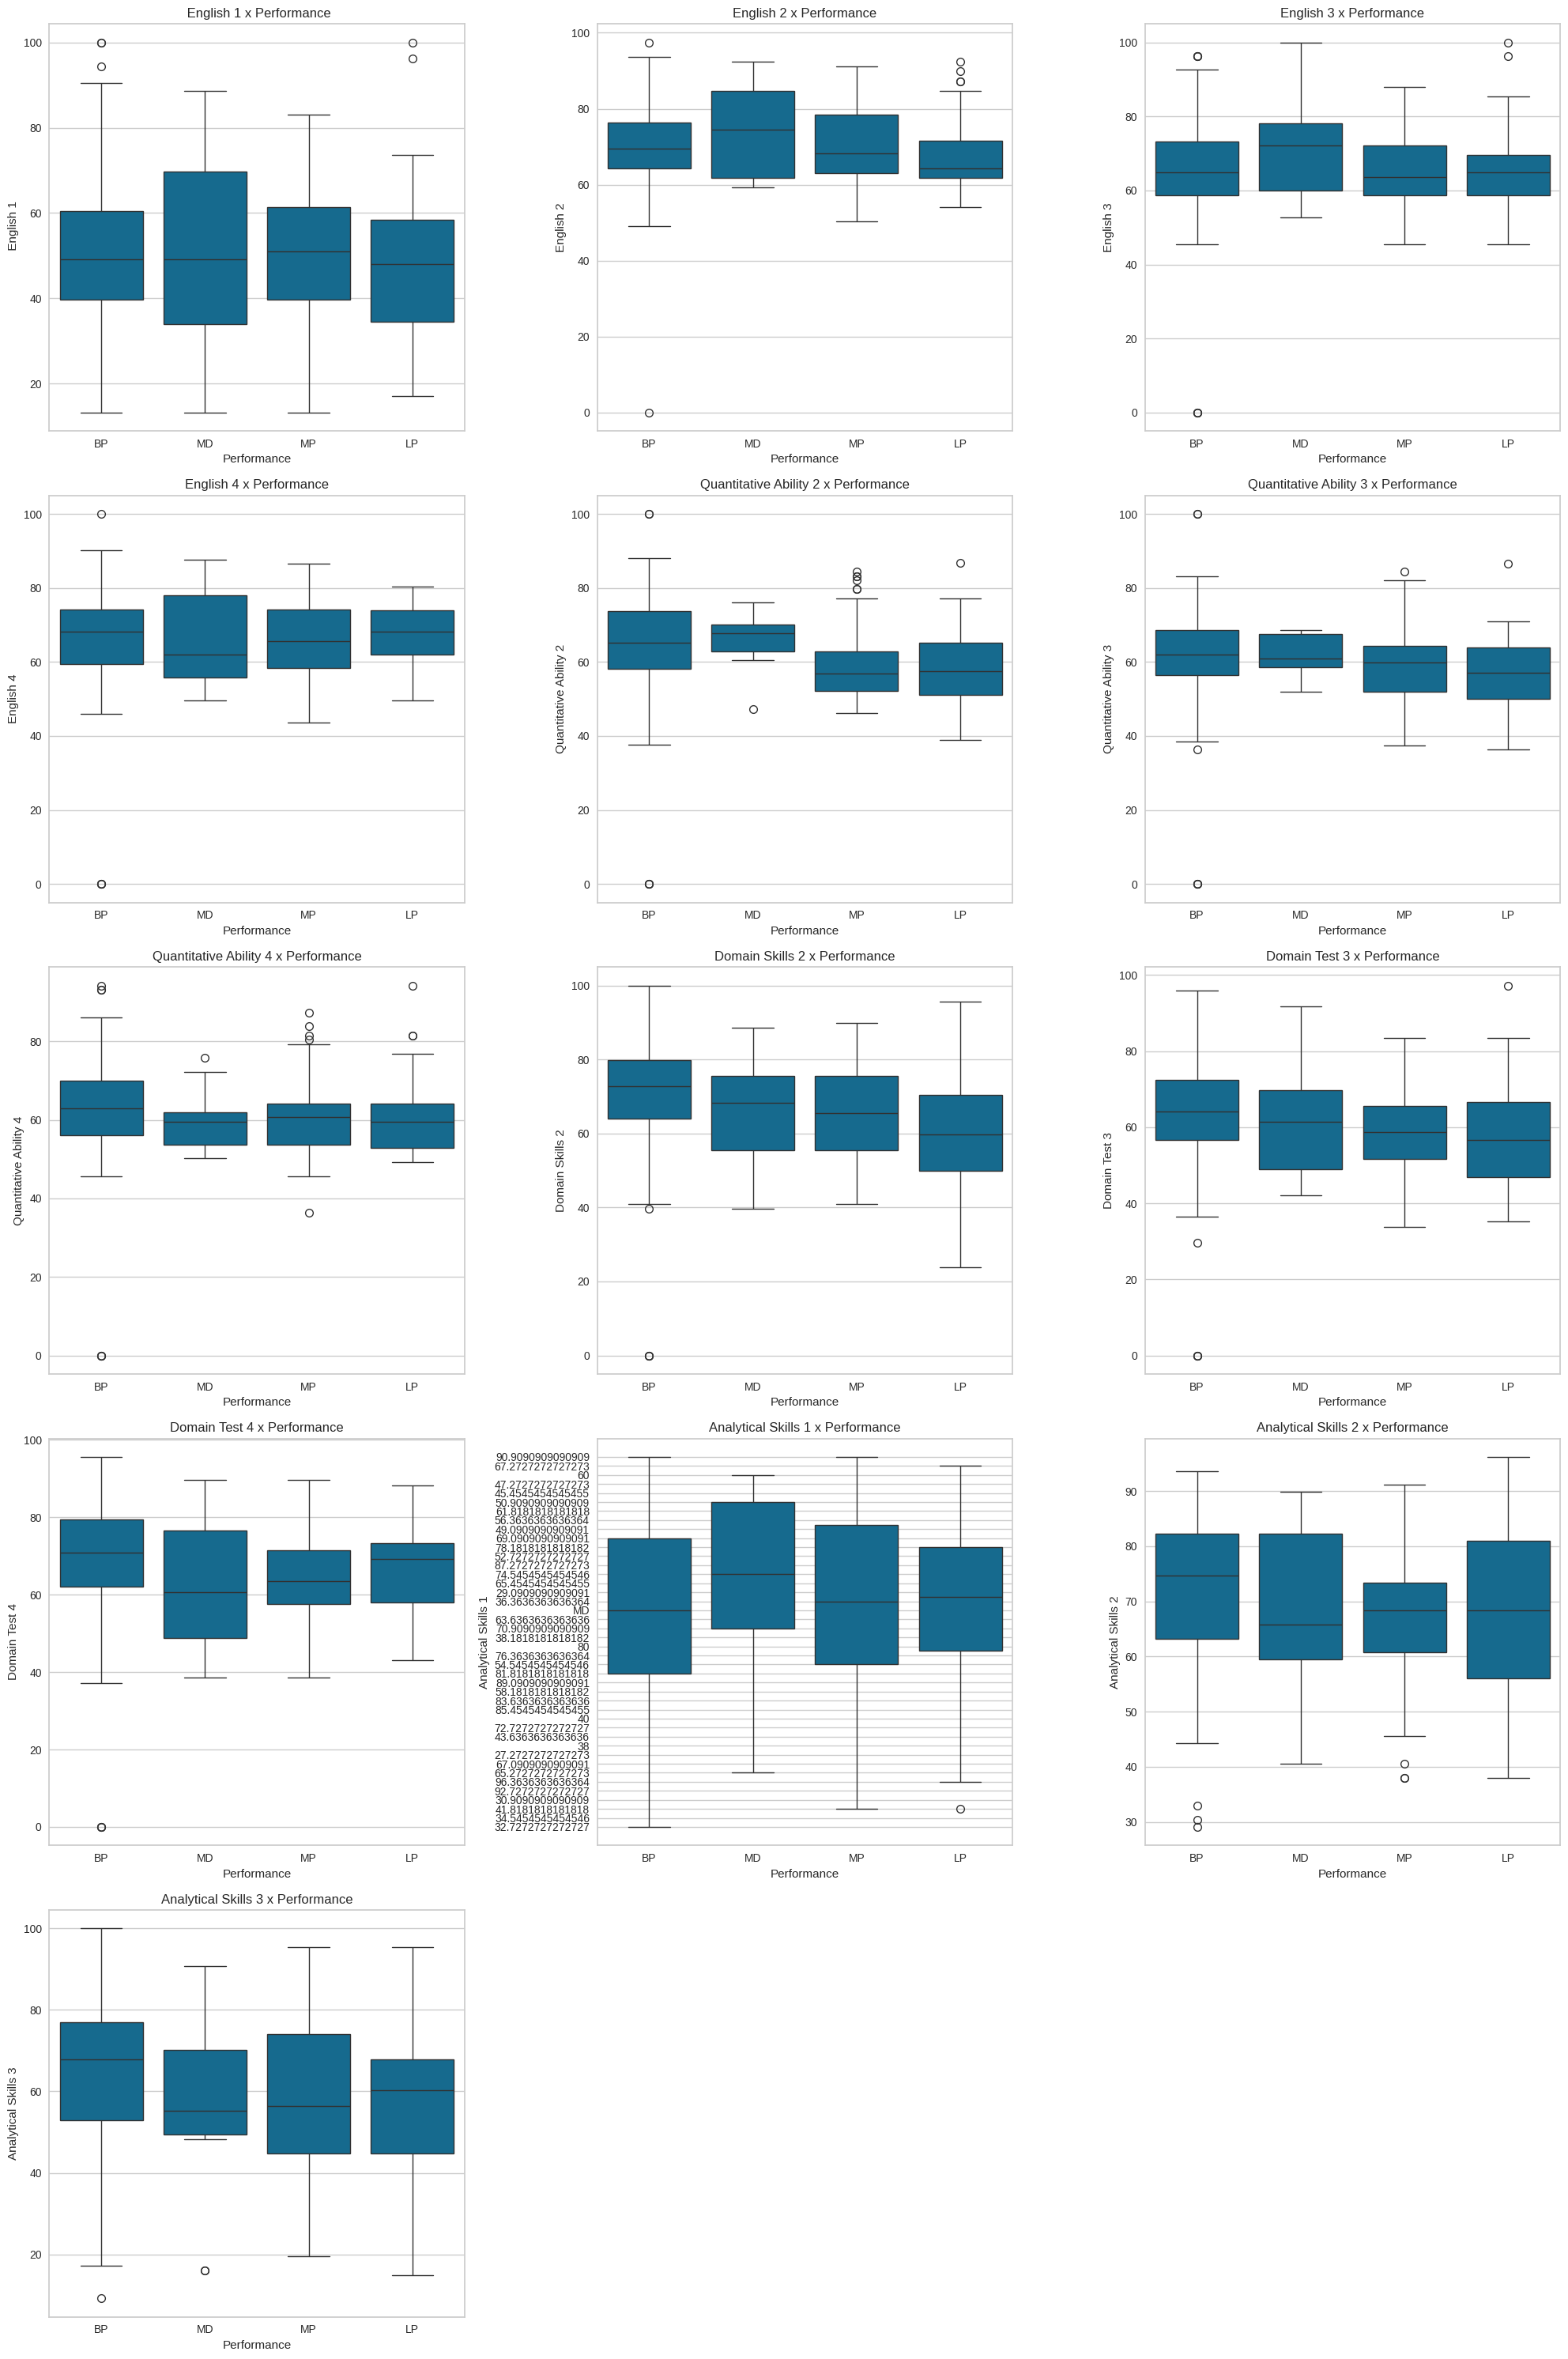

In [ ]:
skills_columns = [' English 1', 'English 2', 'English 3', 'English 4',
                  'Quantitative Ability 2', 'Quantitative Ability 3',
                  'Quantitative Ability 4', 'Domain Skills 2', 'Domain Test 3',
                  'Domain Test 4', 'Analytical Skills 1', 'Analytical Skills 2', 'Analytical Skills 3']

plt.figure(figsize=(20, 30))
for i, col in enumerate(skills_columns, 1):
    plt.subplot(5, 3, i)
    if col in data.columns:
        sns.boxplot(x="Performance", y=col, data=data)
        plt.title(f'{col} x Performance')
    else:
        print(f"Column '{col}' not found in DataFrame.")
plt.tight_layout()
plt.show()

##identificando outliers nas colunas de skill

###Resolvendo questões relacionadas a dados faltantes/vazios

In [ ]:
# Tratando valores 'MD' na classe Performance e dropando eles
data = data[data['Performance'] != 'MD']

##CONFERINDO A CONTAGEM DE MDs
print(data[data == 'MD'].count())

Candidate ID                             0
Name                                     0
Number of characters in Original Name    0
Month of Birth                           0
Year of Birth                            0
Gender                                   0
State (Location)                         0
 10th percentage                         0
 12th percentage                         0
10th Completion Year                     0
12th Completion year                     0
Degree of study                          0
Specialization in study                  0
 College percentage                      0
 Year of Completion of college           0
 English 1                               0
English 2                                0
English 3                                0
English 4                                0
Quantitative Ability 1                   6
Quantitative Ability 2                   0
Quantitative Ability 3                   0
Quantitative Ability 4                   0
Domain Skil

In [ ]:
##tratando valores 'MD' nas colunas 'Analytical Skills 1', 'Domain Skills 1' e 'Quantitative Skills 1'
##a ideia será substituir pela mediana, evitando influencias de outliers

data['Analytical Skills 1'] = data['Analytical Skills 1'].replace('MD', np.nan)
data['Analytical Skills 1'] = pd.to_numeric(data['Analytical Skills 1'], errors='coerce')
data['Analytical Skills 1'].fillna(data['Analytical Skills 1'].median(), inplace=True)

data['Domain Skills 1'] = data['Domain Skills 1'].replace('MD', np.nan)
data['Domain Skills 1'] = pd.to_numeric(data['Domain Skills 1'], errors='coerce')
data['Domain Skills 1'].fillna(data['Domain Skills 1'].median(), inplace=True)

data['Quantitative Ability 1'] = data['Quantitative Ability 1'].replace('MD', np.nan)
data['Quantitative Ability 1'] = pd.to_numeric(data['Quantitative Ability 1'], errors='coerce')
data['Quantitative Ability 1'].fillna(data['Quantitative Ability 1'].median(), inplace=True)

<ipython-input-25-fb5dcaf77138>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Analytical Skills 1'] = data['Analytical Skills 1'].replace('MD', np.nan)
<ipython-input-25-fb5dcaf77138>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Analytical Skills 1'] = pd.to_numeric(data['Analytical Skills 1'], errors='coerce')
<ipython-input-25-fb5dcaf77138>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.

In [ ]:
##verificando se a substiuição funcionou:
data[data == 'MD'].count()

,0
Candidate ID,0
Name,0
Number of characters in Original Name,0
Month of Birth,0
Year of Birth,0
Gender,0
State (Location),0
10th percentage,0
12th percentage,0
10th Completion Year,0


###Transformando dados para numericos de mesma escala para facilitar uso de métodos de estudo futuros

###Tratando Outliers usando IQR com 1.5 como parametro de multiplicação

In [ ]:
print(data.shape)

# Aplicar a regra de IQR apenas nas colunas numéricas
q1 = data[num_columns].quantile(0.25)
q3 = data[num_columns].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Remover os outliers com base nos limites
data = data[~((data[num_columns] < limite_inferior) | (data[num_columns] > limite_superior)).any(axis=1)]

print(data.shape)

(452, 31)
(411, 31)


###Dropando colunas que não fazem sentido interferirem no resultado da perfomance das pessoas analisadas

In [ ]:
data = data.drop(['Candidate ID', 'Number of characters in Original Name', 'Name', 'Month of Birth', 'Year of Birth', 'Gender', 'State (Location)'], axis=1)

###Dividindo o dataframe em X e y (preditores e o que eu quero prever)

In [ ]:
X, y = data.drop('Performance', axis=1), data['Performance']

In [ ]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 411 entries, 0 to 468
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0    10th percentage                411 non-null    float64
 1    12th percentage                411 non-null    float64
 2   10th Completion Year            411 non-null    object 
 3   12th Completion year            411 non-null    object 
 4   Degree of study                 411 non-null    object 
 5   Specialization in study         411 non-null    object 
 6    College percentage             411 non-null    float64
 7    Year of Completion of college  411 non-null    object 
 8    English 1                      411 non-null    float64
 9   English 2                       411 non-null    float64
 10  English 3                       411 non-null    float64
 11  English 4                       411 non-null    float64
 12  Quantitative Ability 1          411 non-n

###Tranformando colunas categoricas em numericas

In [ ]:
print(X)

      10th percentage   12th percentage 10th Completion Year  \
0               83.80             84.00                  Y13   
1               84.40             77.00                  Y14   
2               86.26             62.83                  Y14   
3               81.00             72.00                  Y14   
6               81.45             88.25                  Y14   
..                ...               ...                  ...   
464             67.00             75.60                  Y14   
465             83.20             83.33                  Y10   
466             82.20             81.20                  Y14   
467             89.45             96.25                  Y14   
468             86.20             80.40                  Y13   

    12th Completion year Degree of study Specialization in study  \
0                    Y15               X                       B   
1                    Y16               X                       B   
2                    Y16   

In [ ]:
##realizar o label encoder nas colunas que precisam

label_encoder = LabelEncoder()

for i in range(X.shape[1]):
  if X.iloc[:, i].dtype == 'object':
    X.iloc[:, i] = label_encoder.fit_transform(X.iloc[:, i])

X.head()

,10th percentage,12th percentage,10th Completion Year,12th Completion year,Degree of study,Specialization in study,College percentage,Year of Completion of college,English 1,English 2,...,Quantitative Ability 2,Quantitative Ability 3,Quantitative Ability 4,Domain Skills 1,Domain Skills 2,Domain Test 3,Domain Test 4,Analytical Skills 1,Analytical Skills 2,Analytical Skills 3
0,83.80,84.00,2,2,1,0,62.20,1,52.830189,64.331210,...,65.269461,65.363128,63.005780,48.214286,68.345324,68.275862,59.124088,90.909091,81.012658,95.402299
1,84.40,77.00,3,3,1,0,74.00,1,33.962264,64.331210,...,58.083832,56.424581,65.317919,50.000000,66.906475,68.275862,60.583942,67.272727,88.607595,56.321839
2,86.26,62.83,3,3,1,4,64.29,1,43.396226,69.426752,...,37.724551,50.837989,52.601156,46.428571,56.834532,72.413793,64.963504,60.000000,79.746835,32.183908
3,81.00,72.00,3,3,1,0,79.28,1,62.264151,88.535032,...,54.491018,55.307263,56.069364,35.714286,53.956835,71.034483,50.364964,47.272727,73.417722,35.632184
6,81.45,88.25,3,3,1,0,78.50,1,49.056604,73.248408,...,61.676647,58.659218,49.132948,46.428571,69.784173,47.586207,82.481752,61.818182,50.632911,67.816092


In [ ]:
print(X.shape)

(411, 23)


###Colocando todas as colunas na mesma escala

In [ ]:
##realizando o minmaxscaler para colocar todos os valores na mesma escala
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
X.head()

,10th percentage,12th percentage,10th Completion Year,12th Completion year,Degree of study,Specialization in study,College percentage,Year of Completion of college,English 1,English 2,...,Quantitative Ability 2,Quantitative Ability 3,Quantitative Ability 4,Domain Skills 1,Domain Skills 2,Domain Test 3,Domain Test 4,Analytical Skills 1,Analytical Skills 2,Analytical Skills 3
0,0.584010,0.628415,0.666667,0.4,0.333333,0.0,0.169842,1.0,0.583333,0.342857,...,0.547619,0.609756,0.534884,0.395833,0.488372,0.555556,0.324324,0.918919,0.739130,0.945946
1,0.603510,0.437158,1.000000,0.6,0.333333,0.0,0.491018,1.0,0.305556,0.342857,...,0.404762,0.414634,0.581395,0.416667,0.465116,0.555556,0.351351,0.567568,0.869565,0.486486
2,0.663958,0.050000,1.000000,0.6,0.333333,0.5,0.226728,1.0,0.444444,0.457143,...,0.000000,0.292683,0.325581,0.375000,0.302326,0.622222,0.432432,0.459459,0.717391,0.202703
3,0.493013,0.300546,1.000000,0.6,0.333333,0.0,0.634731,1.0,0.722222,0.885714,...,0.333333,0.390244,0.395349,0.250000,0.255814,0.600000,0.162162,0.270270,0.608696,0.243243
4,0.507637,0.744536,1.000000,0.6,0.333333,0.0,0.613500,1.0,0.527778,0.542857,...,0.476190,0.463415,0.255814,0.375000,0.511628,0.222222,0.756757,0.486486,0.217391,0.621622


###Matriz de Correlação

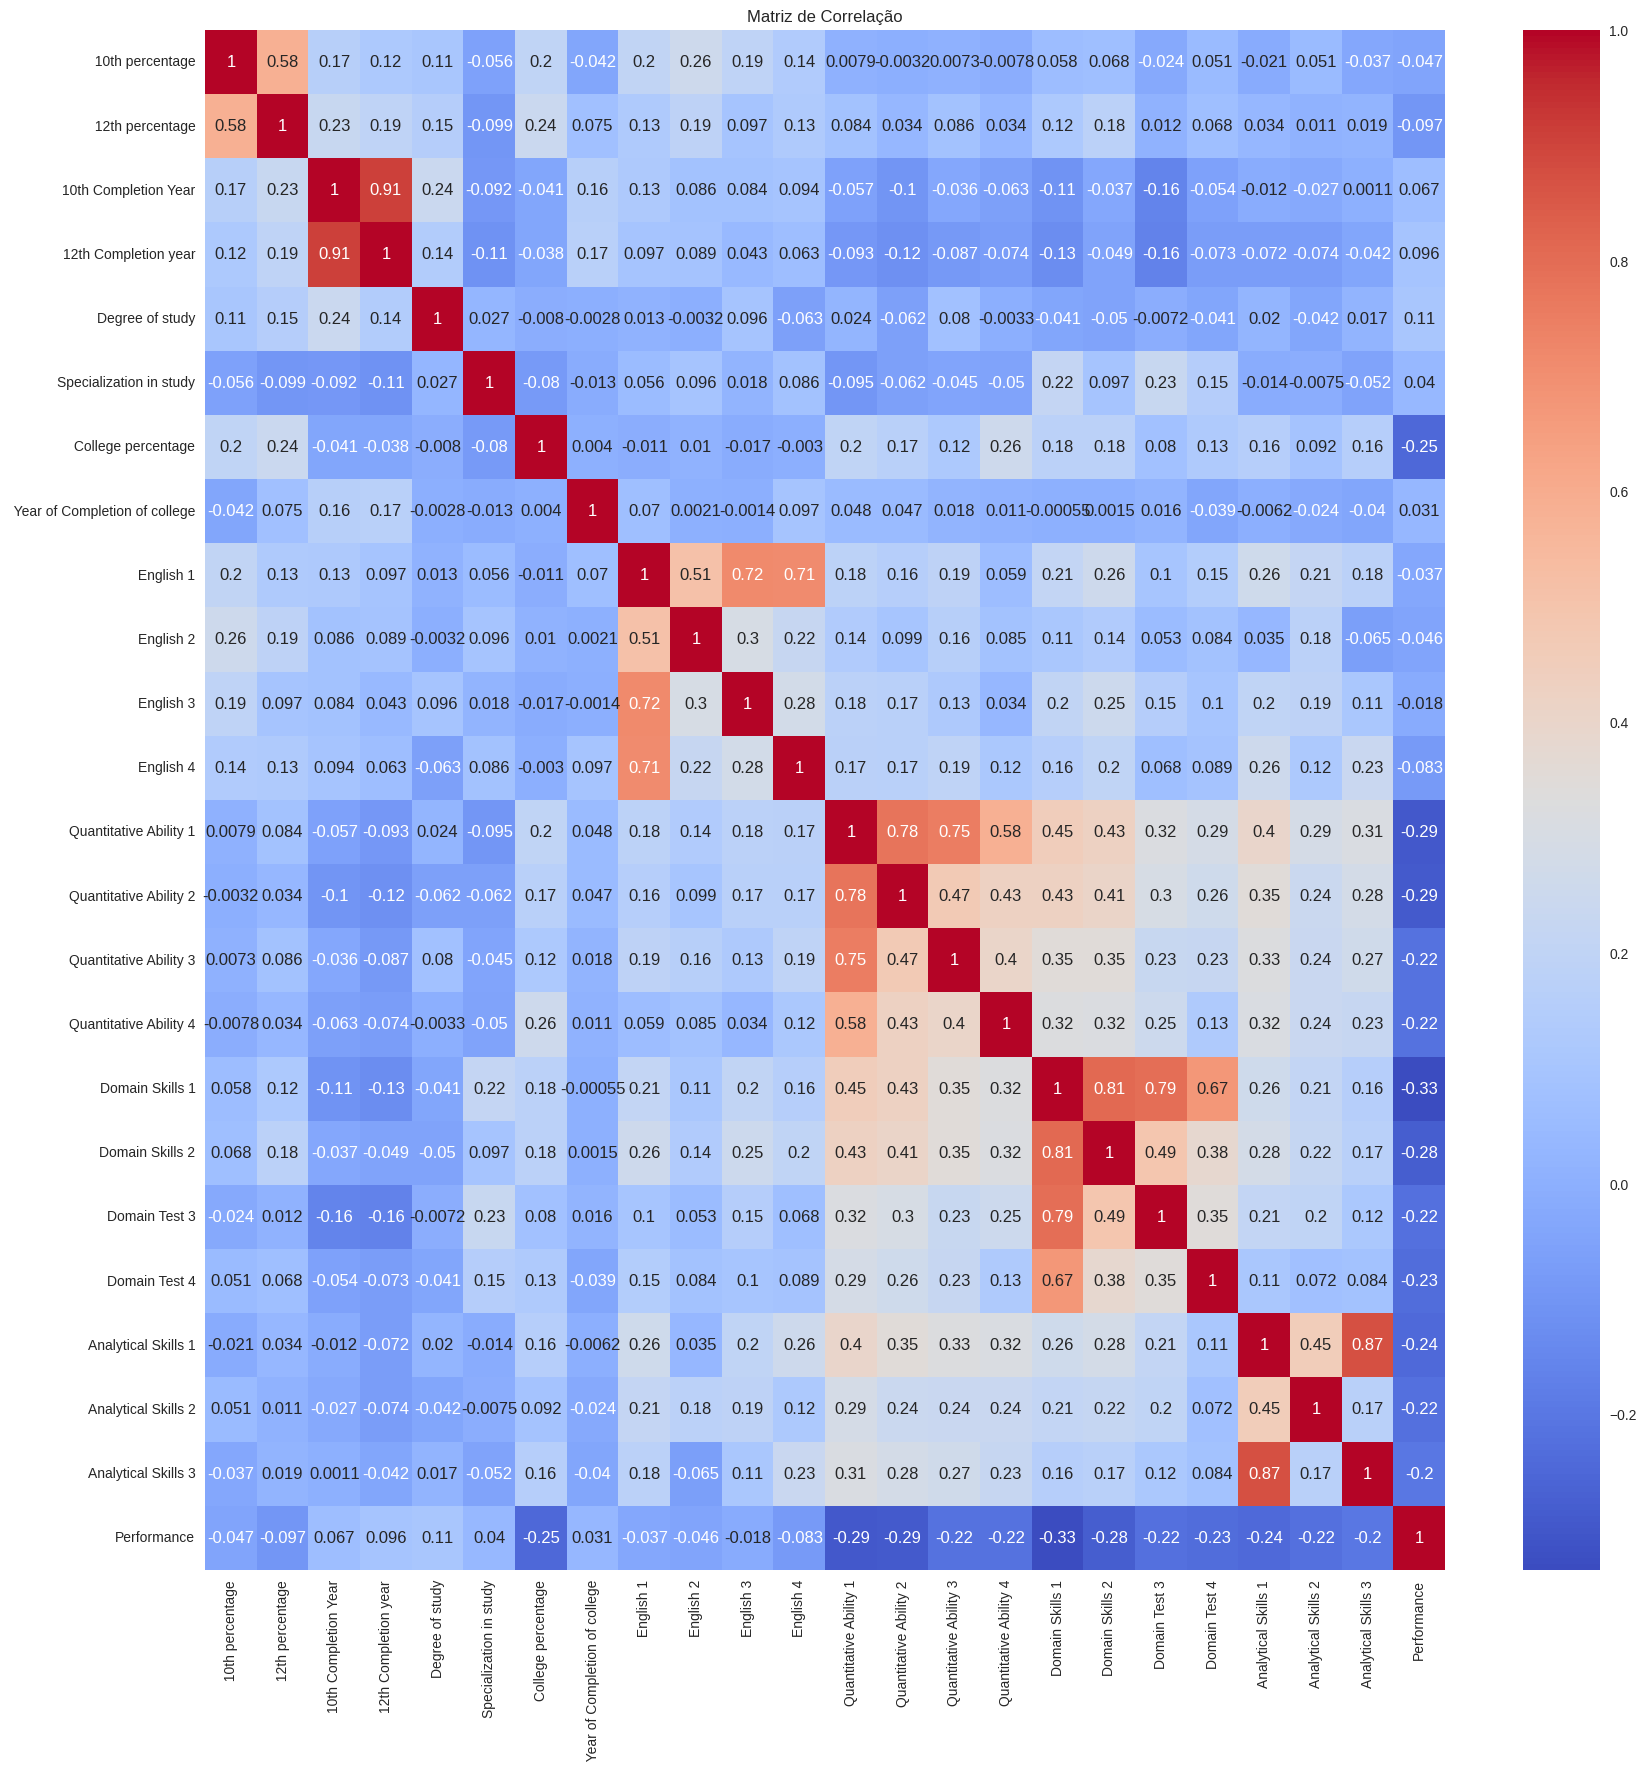

In [ ]:
##construindo uma matriz de correlação basica
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
y_encoded = pd.DataFrame(y_encoded, columns=['Performance'])
corr_matrix = pd.merge(X, y_encoded, left_index=True, right_index=True).corr()

plt.figure(figsize=(20, 20))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlação')
plt.show()

##identificando quais colunas sao mais importantes para determinar a perfomance

###Criando colunas agrupadas entre cada tipo de materias

In [ ]:
##agrupando as materias de domains em so uma atributo e trabalhando apenas com essa coluna geral no dataset apra realizar a previsao
X['Domain Skills'] = X[['Domain Skills 1', 'Domain Skills 2', 'Domain Test 3', 'Domain Test 4']].sum(axis=1)/4
X['Analytical Skills'] = X[['Analytical Skills 1', 'Analytical Skills 2', 'Analytical Skills 3']].sum(axis=1)/3
X['Quantitative Ability'] = X[['Quantitative Ability 1', 'Quantitative Ability 2', 'Quantitative Ability 3', 'Quantitative Ability 4']].sum(axis=1)/4
X['English'] = X[[' English 1', 'English 2', 'English 3', 'English 4']].sum(axis=1)/4

X.drop(['Domain Skills 1', 'Domain Skills 2', 'Domain Test 3', 'Domain Test 4', 'Analytical Skills 1', 'Analytical Skills 2', 'Analytical Skills 3', 'Quantitative Ability 1', 'Quantitative Ability 2', 'Quantitative Ability 3', 'Quantitative Ability 4'], axis=1, inplace=True)
X.drop([' English 1', 'English 2', 'English 3', 'English 4'], axis=1, inplace=True)

X.head()

,10th percentage,12th percentage,10th Completion Year,12th Completion year,Degree of study,Specialization in study,College percentage,Year of Completion of college,Domain Skills,Analytical Skills,Quantitative Ability,English
0,0.584010,0.628415,0.666667,0.4,0.333333,0.0,0.169842,1.0,0.441021,0.867998,0.556786,0.498440
1,0.603510,0.437158,1.000000,0.6,0.333333,0.0,0.491018,1.0,0.447172,0.641206,0.466477,0.319949
2,0.663958,0.050000,1.000000,0.6,0.333333,0.5,0.226728,1.0,0.432995,0.459851,0.160380,0.437859
3,0.493013,0.300546,1.000000,0.6,0.333333,0.0,0.634731,1.0,0.316994,0.374070,0.372755,0.703974
4,0.507637,0.744536,1.000000,0.6,0.333333,0.0,0.613500,1.0,0.466402,0.441833,0.409320,0.472426


###SelectKBest

In [ ]:
# from sklearn.decomposition import PCA

# pca = PCA(n_components=4)
# X_novo = pca.fit_transform(X)

In [ ]:
selecao = SelectKBest(score_func=f_classif, k=3)
X_novo = selecao.fit_transform(X, y_encoded)
selecionadas = selecao.get_support(indices=True)
colunas_selecionadas = X.columns[selecionadas]
print(colunas_selecionadas)

Index([' College percentage', 'Domain Skills', 'Quantitative Ability'], dtype='object')


/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1183: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [ ]:
print(y)

0      BP
1      BP
2      BP
3      BP
6      BP
       ..
464    LP
465    MP
466    BP
467    BP
468    BP
Name: Performance, Length: 411, dtype: object


In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X_novo, y, test_size=0.2, random_state=42)

###GaussianNB

In [ ]:
modelNB = GaussianNB()

modelNB.fit(X_treino, y_treino)

GaussianNB()

In [ ]:
previsoesNB = modelNB.predict(X_teste)
previsoesNB

array(['BP', 'BP', 'BP', 'MP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP',
       'MP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'MP',
       'BP', 'BP', 'BP', 'BP', 'MP', 'MP', 'MP', 'BP', 'MP', 'LP', 'BP',
       'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP',
       'MP', 'MP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'MP', 'BP', 'MP',
       'BP', 'MP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'MP', 'BP', 'BP',
       'BP', 'BP', 'MP', 'BP', 'BP', 'BP', 'LP', 'MP', 'BP', 'BP', 'MP',
       'BP', 'BP', 'BP', 'BP', 'MP', 'MP'], dtype='<U2')

In [ ]:
print(y_teste.to_list())

['BP', 'BP', 'BP', 'LP', 'LP', 'MP', 'BP', 'MP', 'LP', 'BP', 'LP', 'BP', 'BP', 'BP', 'MP', 'BP', 'BP', 'BP', 'MP', 'BP', 'MP', 'BP', 'MP', 'BP', 'BP', 'MP', 'BP', 'BP', 'LP', 'BP', 'LP', 'MP', 'BP', 'BP', 'BP', 'MP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'LP', 'LP', 'BP', 'LP', 'BP', 'MP', 'BP', 'LP', 'BP', 'MP', 'LP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'MP', 'BP', 'MP', 'MP', 'MP', 'BP', 'BP', 'MP', 'LP', 'BP', 'BP', 'BP', 'LP', 'MP', 'BP', 'MP', 'BP', 'BP', 'BP', 'BP', 'MP', 'BP']


In [ ]:
acuraciaNB = accuracy_score(y_teste, previsoesNB)
# f1_score = f1_score(y_teste, previsoes, average='weighted')
precisionNB = precision_score(y_teste, previsoesNB, average='weighted')
recallNB = recall_score(y_teste, previsoesNB, average='weighted')

print(f'Acurácia: {acuraciaNB:.4f}')
# print(f'F1 Score: {f1_score:.4f}')
print(f'Precision: {precisionNB:.4f}')
print(f'Recall: {recallNB:.4f}')

Acurácia: 0.5663
Precision: 0.4703
Recall: 0.5663


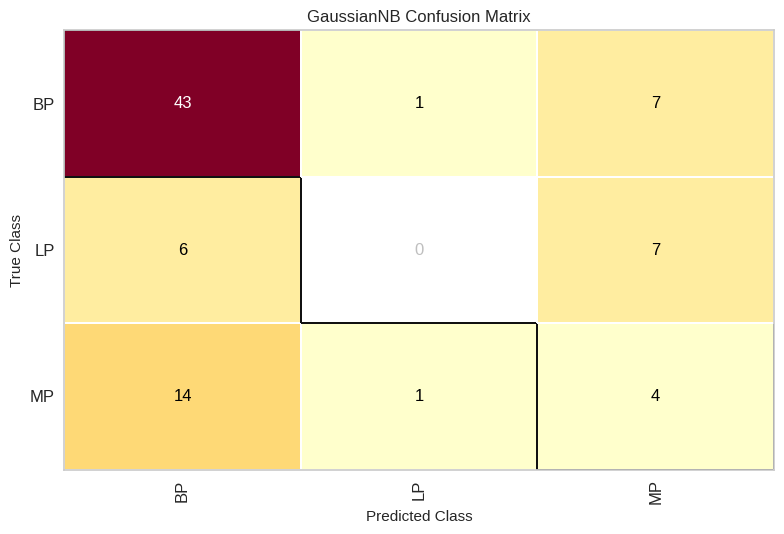

<Axes: title={'center': 'GaussianNB Confusion Matrix'}, xlabel='Predicted Class', ylabel='True Class'>

In [ ]:
matriz_confusao = ConfusionMatrix(modelNB)
matriz_confusao.fit(X_treino, y_treino)
matriz_confusao.score(X_teste, y_teste)
matriz_confusao.show()

###Random Forest Classifier

In [ ]:
modelRFC = RandomForestClassifier( random_state=42)

modelRFC.fit(X_treino, y_treino)

RandomForestClassifier(random_state=42)

In [ ]:
param_grid = {
    'n_estimators': [100, 300, 500],  # Testar mais estimadores
    'max_depth': [10, 20, 30, 40],  # Aumentar a profundidade
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]  # Adicionando nova variável
}

grid_search = GridSearchCV(modelRFC, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_treino, y_treino)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [10, 20, 30, 40],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 300, 500]},
             scoring='accuracy')

In [ ]:
best_rf = grid_search.best_estimator_
previsoesRFC = best_rf.predict(X_teste)
previsoesRFC

array(['BP', 'BP', 'BP', 'MP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP',
       'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'MP', 'BP', 'BP', 'BP',
       'BP', 'BP', 'BP', 'BP', 'MP', 'BP', 'LP', 'BP', 'MP', 'LP', 'BP',
       'BP', 'BP', 'MP', 'BP', 'BP', 'MP', 'BP', 'BP', 'BP', 'BP', 'BP',
       'MP', 'MP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'LP',
       'BP', 'MP', 'BP', 'BP', 'BP', 'BP', 'MP', 'BP', 'LP', 'MP', 'BP',
       'BP', 'BP', 'MP', 'LP', 'BP', 'MP', 'LP', 'MP', 'BP', 'BP', 'MP',
       'BP', 'BP', 'BP', 'BP', 'MP', 'MP'], dtype=object)

In [ ]:
print(y_teste.to_list())

['BP', 'BP', 'BP', 'LP', 'LP', 'MP', 'BP', 'MP', 'LP', 'BP', 'LP', 'BP', 'BP', 'BP', 'MP', 'BP', 'BP', 'BP', 'MP', 'BP', 'MP', 'BP', 'MP', 'BP', 'BP', 'MP', 'BP', 'BP', 'LP', 'BP', 'LP', 'MP', 'BP', 'BP', 'BP', 'MP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'LP', 'LP', 'BP', 'LP', 'BP', 'MP', 'BP', 'LP', 'BP', 'MP', 'LP', 'BP', 'BP', 'BP', 'BP', 'BP', 'BP', 'MP', 'BP', 'MP', 'MP', 'MP', 'BP', 'BP', 'MP', 'LP', 'BP', 'BP', 'BP', 'LP', 'MP', 'BP', 'MP', 'BP', 'BP', 'BP', 'BP', 'MP', 'BP']


In [ ]:
acuraciaRFC = accuracy_score(y_teste, previsoesRFC)
# f1_score = f1_score(y_teste, previsoes, average='weighted')
precisionRFC = precision_score(y_teste, previsoesRFC, average='weighted')
recallRFC = recall_score(y_teste, previsoesRFC, average='weighted')

print(f'Acurácia: {acuraciaRFC:.4f}')
# print(f'F1 Score: {f1_score:.4f}')
print(f'Precision: {precisionRFC:.4f}')
print(f'Recall: {recallRFC:.4f}')

##com k=3: 0.7229 acc
##com k=4: 0.65 acc
##com k=2: 0.59
##com k=5: 0.63

Acurácia: 0.6627
Precision: 0.6334
Recall: 0.6627


###Redes Neurais

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.utils import to_categorical

In [ ]:
y_treino_encoded = label_encoder.fit_transform(y_treino)
y_teste_encoded = label_encoder.transform(y_teste)

# Converter as classes inteiras para one-hot encoding
y_treino_onehot = to_categorical(y_treino_encoded, num_classes=3)
y_teste_onehot = to_categorical(y_teste_encoded, num_classes=3)

In [ ]:
modelo = Sequential()
modelo.add(Dense(units=64, activation='relu', input_dim=X_treino.shape[1]))
modelo.add(Dropout(0.3))  # Aumentando o dropout para evitar overfitting
modelo.add(Dense(units=32, activation='relu'))
modelo.add(Dropout(0.3))
modelo.add(Dense(units=16, activation='relu'))
modelo.add(Dense(units=3, activation='softmax'))  # Três classes, por isso 3 saídas

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
print(y_teste)

192    BP
37     BP
81     BP
414    LP
424    LP
       ..
381    BP
7      BP
52     BP
106    MP
330    BP
Name: Performance, Length: 83, dtype: object


In [ ]:
# Convert target variable to one-hot encoded format
y_treino = to_categorical(y_treino_onehot, num_classes=3)

In [ ]:
modelo.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

modelo.fit(X_treino, y_treino_onehot, epochs=50, batch_size=32, validation_data=(X_teste, y_teste_onehot))

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.2023 - loss: 1.1453 - val_accuracy: 0.6145 - val_loss: 1.0608
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5594 - loss: 1.0475 - val_accuracy: 0.6145 - val_loss: 1.0213
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7020 - loss: 0.9743 - val_accuracy: 0.6145 - val_loss: 0.9795
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7210 - loss: 0.8920 - val_accuracy: 0.6145 - val_loss: 0.9280
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7035 - loss: 0.8346 - val_accuracy: 0.6145 - val_loss: 0.9024
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7194 - loss: 0.7489 - val_accuracy: 0.6145 - val_loss: 0.9124
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7120 - loss: 0.7602 - val_accuracy: 0.6145 - val_loss: 0.9246
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6914 - loss: 0.7801 - val_accuracy: 0.6145 - val_lo

In [ ]:
previsoesRN = modelo.predict(X_teste)

previsoesRN

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


array([[0.7537135 , 0.06032808, 0.18595843],
       [0.6507865 , 0.11308646, 0.23612702],
       [0.5986398 , 0.13307194, 0.26828814],
       [0.51786584, 0.17706609, 0.30506796],
       [0.7366972 , 0.06314235, 0.2001604 ],
       [0.7431861 , 0.0682898 , 0.18852411],
       [0.8876367 , 0.02130541, 0.09105776],
       [0.73760563, 0.0716995 , 0.19069482],
       [0.7102037 , 0.08392697, 0.20586924],
       [0.73394793, 0.07553315, 0.19051883],
       [0.7366972 , 0.06314235, 0.2001604 ],
       [0.55107003, 0.15465748, 0.2942724 ],
       [0.92127824, 0.01284087, 0.06588089],
       [0.715631  , 0.07833127, 0.2060377 ],
       [0.58871025, 0.1405129 , 0.27077693],
       [0.7423594 , 0.07375198, 0.18388863],
       [0.85404986, 0.03467221, 0.1112779 ],
       [0.826205  , 0.04259781, 0.13119718],
       [0.70121145, 0.08733191, 0.21145663],
       [0.89971805, 0.0170566 , 0.08322541],
       [0.8240233 , 0.04221378, 0.13376288],
       [0.625281  , 0.10587639, 0.2688428 ],
       [0.

In [ ]:
# Convert predicted probabilities to class labels
previsoesRN = np.argmax(previsoesRN, axis=1)

In [ ]:
acuraciaRN = accuracy_score(y_teste, previsoesRN)
print(f'Acurácia: {acuraciaRN:.4f}')


Acurácia: 0.0000
